In [8]:
# Common Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Common libraries imported successfully")

Common libraries imported successfully


In [9]:
# Load Dataset

df = pd.read_csv("/home/aditya/Downloads/data.csv")

print("Dataset loaded successfully")
print("Dataset Shape:", df.shape)
print(df.head())

Dataset loaded successfully
Dataset Shape: (569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  t

In [10]:
# Prepare Breast Cancer Data for Experiments 05–11

X = df.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)

X = X.select_dtypes(include=[np.number])
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

y = df["diagnosis"].map({"M": 1, "B": 0})

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)
print("Common setup completed successfully")

Input Shape: (569, 30)
Output Shape: (569,)
Common setup completed successfully


In [11]:
%pip install pgmpy networkx

Note: you may need to restart the kernel to use updated packages.


/home/aditya/AIDS_EXP/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/aditya/AIDS_EXP/.venv/lib/python3.13/site-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Bayesian Network Valid: True

Posterior Probability for Guest=2, Price=2:
+---------+-------------+
| Host    |   phi(Host) |
+=========+=============+
| Host(0) |      0.5000 |
+---------+-------------+
| Host(1) |      0.5000 |
+---------+-------------+
| Host(2) |      0.0000 |
+---------+-------------+

Posterior Probability for Guest=1, Price=2:
+---------+-------------+
| Host    |   phi(Host) |
+=========+=============+
| Host(0) |      1.0000 |
+---------+-------------+
| Host(1) |      0.0000 |
+---------+-------------+
| Host(2) |      0.0000 |
+---------+-------------+


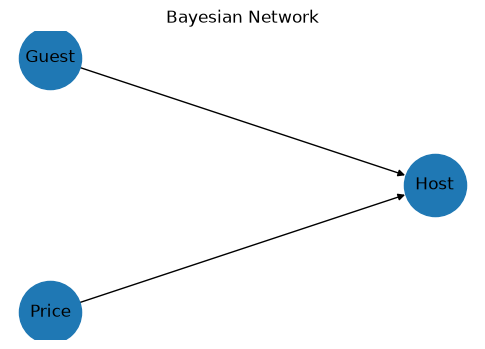

In [26]:
# Experiment 01: Bayesian Network

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
import networkx as nx

# Define the Bayesian Network Structure

model = DiscreteBayesianNetwork([
    ("Guest", "Host"),
    ("Price", "Host")
])

# Define Conditional Probability Distributions (CPDs)

cpd_guest = TabularCPD(
    variable="Guest",
    variable_card=3,
    values=[[1/3], [1/3], [1/3]]
)

cpd_price = TabularCPD(
    variable="Price",
    variable_card=3,
    values=[[1/3], [1/3], [1/3]]
)

cpd_host = TabularCPD(
    variable="Host",
    variable_card=3,
    values=[
        [0, 0, 0, 0, 0.5, 1, 0, 1, 0.5],
        [0.5, 0, 1, 0, 0, 0, 1, 0, 0.5],
        [0.5, 1, 0, 1, 0.5, 0, 0, 0, 0]
    ],
    evidence=["Guest", "Price"],
    evidence_card=[3, 3]
)

# Add CPDs to the Model

model.add_cpds(cpd_guest, cpd_price, cpd_host)

print("Bayesian Network Valid:", model.check_model())

# Perform Inference

infer = VariableElimination(model)

print("\nPosterior Probability for Guest=2, Price=2:")

posterior_p = infer.query(
    variables=["Host"],
    evidence={"Guest": 2, "Price": 2}
)

print(posterior_p)

print("\nPosterior Probability for Guest=1, Price=2:")

posterior_p = infer.query(
    variables=["Host"],
    evidence={"Guest": 1, "Price": 2}
)

print(posterior_p)

# Draw the Bayesian Network

pos = {
    "Guest": (0, 1),
    "Price": (0, -1),
    "Host": (1, 0)
}

plt.figure(figsize=(6, 4))

nx.draw_networkx(
    model,
    pos=pos,
    with_labels=True,
    node_size=2000,
    arrows=True
)

plt.title("Bayesian Network")
plt.axis("off")
plt.show()

In [17]:
# Experiment 02: Building a Cognitive Application for Insurance

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Insurance Questions

questions = [
    "What is insurance?",
    "What is life insurance?",
    "What is health insurance?",
    "What is insurance premium?",
    "What is deductible?",
    "How can I claim insurance?",
    "What documents are required for an insurance claim?",
    "What is an insurance policy?",
    "What is an insurance claim?",
    "What is car insurance?"
]

# Corresponding Answers

answers = [
    "Insurance is a financial protection system that protects a person or organization against specified risks in exchange for a premium.",
    "Life insurance provides financial protection to the policyholder's beneficiaries in case of the policyholder's death, according to the policy terms.",
    "Health insurance provides financial coverage for eligible medical and healthcare expenses according to the policy terms.",
    "An insurance premium is the amount paid by the policyholder to the insurance company to keep the insurance policy active.",
    "A deductible is the amount that the policyholder may have to pay before the insurance company covers the remaining eligible expenses, depending on the policy.",
    "To claim insurance, the policyholder generally needs to inform the insurer, submit the claim form and provide the required supporting documents.",
    "Common documents may include the policy document, claim form, identity proof, bills, receipts and other documents relevant to the type of claim.",
    "An insurance policy is a contract between the policyholder and the insurance company that specifies the coverage, terms, conditions and exclusions.",
    "An insurance claim is a formal request made by the policyholder to the insurance company for benefits or compensation covered by the policy.",
    "Car insurance provides financial protection against specified risks related to a vehicle, subject to the coverage, terms and conditions of the policy."
]

# Create the TF-IDF Model

vectorizer = TfidfVectorizer()
question_vectors = vectorizer.fit_transform(questions)

print("Insurance knowledge base created successfully!")


# Define the Insurance Assistant

def insurance_assistant(user_query):

    user_vector = vectorizer.transform([user_query])

    similarity = cosine_similarity(
        user_vector,
        question_vectors
    )

    best_match = similarity.argmax()
    score = similarity[0][best_match]

    if score < 0.15:
        return "Sorry, I could not understand your insurance query. Please ask another question."

    return answers[best_match]


# Test the Application

user_query = input("Enter your insurance question: ")

response = insurance_assistant(user_query)

print("\nCognitive Insurance Assistant:")
print(response)

Insurance knowledge base created successfully!


Enter your insurance question:  what is health  insurance



Cognitive Insurance Assistant:
Health insurance provides financial coverage for eligible medical and healthcare expenses according to the policy terms.


In [19]:
%pip install pyit2fls

Note: you may need to restart the kernel to use updated packages.


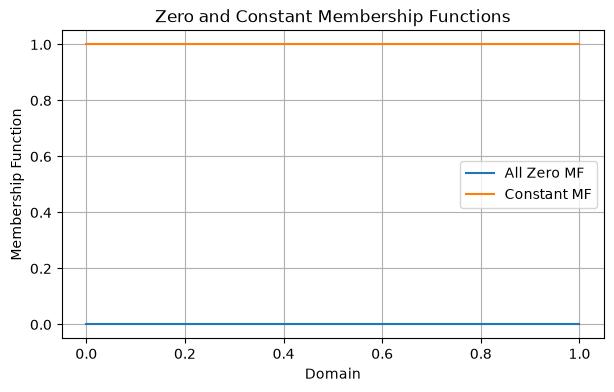

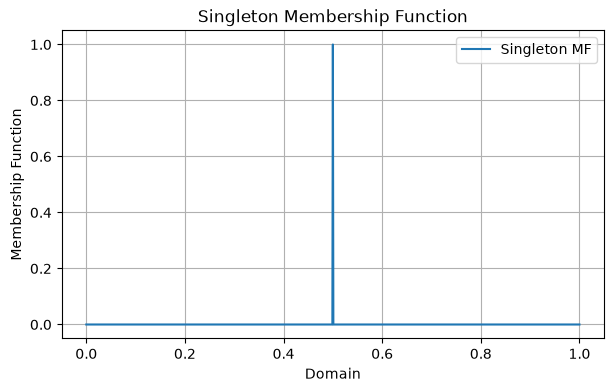

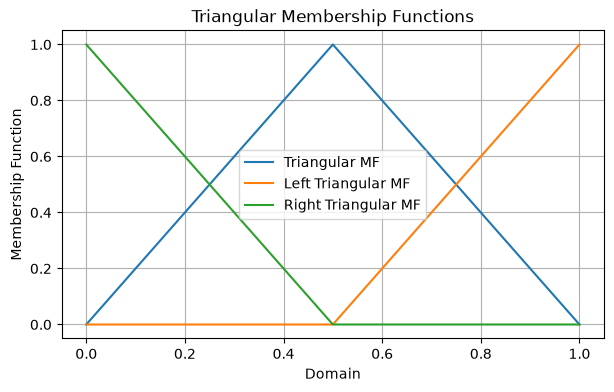

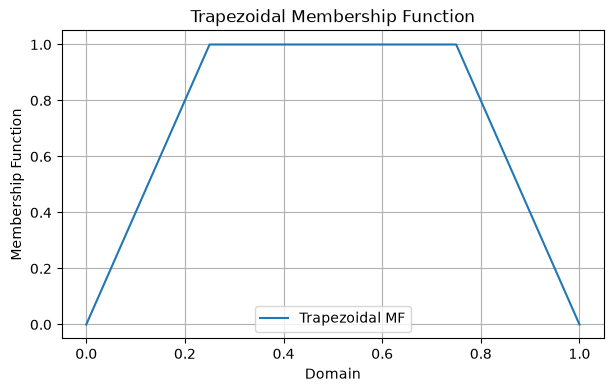

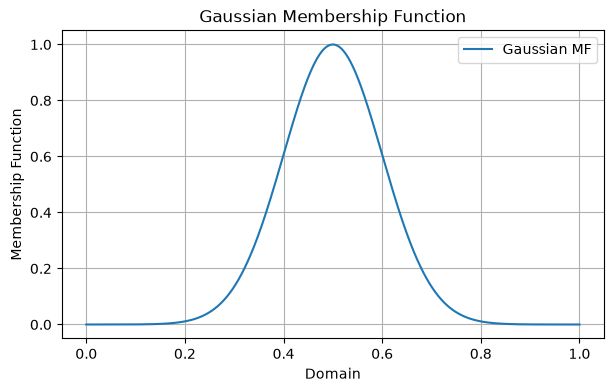

All fuzzy membership functions generated successfully


In [1]:
# Experiment 03: Implementation of Fuzzy Membership Functions

from numpy import linspace
import matplotlib.pyplot as plt

from pyit2fls import (
    zero_mf,
    singleton_mf,
    const_mf,
    tri_mf,
    ltri_mf,
    rtri_mf,
    trapezoid_mf,
    gaussian_mf
)

# Define the Domain

domain = linspace(0.0, 1.0, 1001)

# Generate Membership Functions

zero = zero_mf(domain)
singleton = singleton_mf(domain, [0.5, 1.0])
const = const_mf(domain, [1.0])
tri = tri_mf(domain, [0.0, 0.5, 1.0, 1.0])
ltri = ltri_mf(domain, [0.5, 1.0, 1.0])
rtri = rtri_mf(domain, [0.5, 0.0, 1.0])
trapezoid = trapezoid_mf(domain, [0.0, 0.25, 0.75, 1.0, 1.0])
gaussian = gaussian_mf(domain, [0.5, 0.1, 1.0])

# Plot Zero and Constant Membership Functions

plt.figure(figsize=(7, 4))
plt.plot(domain, zero, label="All Zero MF")
plt.plot(domain, const, label="Constant MF")
plt.grid(True)
plt.legend()
plt.xlabel("Domain")
plt.ylabel("Membership Function")
plt.title("Zero and Constant Membership Functions")
plt.show()

# Plot Singleton Membership Function

plt.figure(figsize=(7, 4))
plt.plot(domain, singleton, label="Singleton MF")
plt.grid(True)
plt.legend()
plt.xlabel("Domain")
plt.ylabel("Membership Function")
plt.title("Singleton Membership Function")
plt.show()

# Plot Triangular Membership Functions

plt.figure(figsize=(7, 4))
plt.plot(domain, tri, label="Triangular MF")
plt.plot(domain, ltri, label="Left Triangular MF")
plt.plot(domain, rtri, label="Right Triangular MF")
plt.grid(True)
plt.legend()
plt.xlabel("Domain")
plt.ylabel("Membership Function")
plt.title("Triangular Membership Functions")
plt.show()

# Plot Trapezoidal Membership Function

plt.figure(figsize=(7, 4))
plt.plot(domain, trapezoid, label="Trapezoidal MF")
plt.grid(True)
plt.legend()
plt.xlabel("Domain")
plt.ylabel("Membership Function")
plt.title("Trapezoidal Membership Function")
plt.show()

# Plot Gaussian Membership Function

plt.figure(figsize=(7, 4))
plt.plot(domain, gaussian, label="Gaussian MF")
plt.grid(True)
plt.legend()
plt.xlabel("Domain")
plt.ylabel("Membership Function")
plt.title("Gaussian Membership Function")
plt.show()

print("All fuzzy membership functions generated successfully")

In [2]:
# Experiment 04: Implementation of Fuzzy Set Properties

import numpy as np

# Define the Fuzzy Set Class

class FuzzySet:

    def __init__(self, iterable):
        self.values = dict(iterable)

        for element, membership in self.values.items():
            if not isinstance(membership, (int, float)):
                raise ValueError("Membership values must be numeric")

            if not 0 <= membership <= 1:
                raise ValueError("Membership values must be between 0 and 1")

    def __or__(self, other):
        # Fuzzy Union
        self._check(other)
        return FuzzySet([
            (x, max(self.values[x], other.values[x]))
            for x in self.values
        ])

    def __and__(self, other):
        # Fuzzy Intersection
        self._check(other)
        return FuzzySet([
            (x, min(self.values[x], other.values[x]))
            for x in self.values
        ])

    def __invert__(self):
        # Fuzzy Complement
        return FuzzySet([
            (x, round(1 - value, 2))
            for x, value in self.values.items()
        ])

    def __sub__(self, other):
        # Fuzzy Difference
        return self & ~other

    def __mul__(self, other):
        # Algebraic Product
        self._check(other)
        return FuzzySet([
            (x, round(self.values[x] * other.values[x], 2))
            for x in self.values
        ])

    def _check(self, other):
        if set(self.values) != set(other.values):
            raise ValueError("Fuzzy sets must contain the same elements")

    def __len__(self):
        return len(self.values)

    def __str__(self):
        return str([
            (x, round(value, 2))
            for x, value in self.values.items()
        ])

    def __getitem__(self, item):
        return list(self.values.items())[item]


# Create Fuzzy Sets

a = FuzzySet([
    ("x1", 0.5),
    ("x2", 0.7),
    ("x3", 0.0)
])

b = FuzzySet([
    ("x1", 0.8),
    ("x2", 0.2),
    ("x3", 1.0)
])

# Display Fuzzy Set Operations

print("a =", a)
print("b =", b)
print("Fuzzy Union:", a | b)
print("Fuzzy Intersection:", a & b)
print("Fuzzy Complement of a:", ~a)
print("Fuzzy Complement of b:", ~b)
print("Fuzzy Difference (a - b):", a - b)
print("Algebraic Product:", a * b)


# Max-Min Composition of Fuzzy Relations

R = np.array([
    [0.6, 0.6, 0.8, 0.9],
    [0.1, 0.2, 0.9, 0.8],
    [0.9, 0.3, 0.4, 0.8],
    [0.9, 0.8, 0.1, 0.2]
])

S = np.array([
    [0.1, 0.2, 0.7, 0.9],
    [1.0, 1.0, 0.4, 0.6],
    [0.0, 0.0, 0.5, 0.9],
    [0.9, 1.0, 0.8, 0.2]
])

def max_min(array1, array2):

    if array1.shape[1] != array2.shape[0]:
        raise ValueError("Matrix dimensions are incompatible")

    result = np.zeros((array1.shape[0], array2.shape[1]))

    for i in range(array1.shape[0]):
        for j in range(array2.shape[1]):
            result[i, j] = max(
                min(array1[i, k], array2[k, j])
                for k in range(array1.shape[1])
            )

    return result


print("\nMax-Min Composition:")
print(np.round(max_min(R, S), 2))

print("\nExperiment 04 completed successfully")

a = [('x1', 0.5), ('x2', 0.7), ('x3', 0.0)]
b = [('x1', 0.8), ('x2', 0.2), ('x3', 1.0)]
Fuzzy Union: [('x1', 0.8), ('x2', 0.7), ('x3', 1.0)]
Fuzzy Intersection: [('x1', 0.5), ('x2', 0.2), ('x3', 0.0)]
Fuzzy Complement of a: [('x1', 0.5), ('x2', 0.3), ('x3', 1.0)]
Fuzzy Complement of b: [('x1', 0.2), ('x2', 0.8), ('x3', 0.0)]
Fuzzy Difference (a - b): [('x1', 0.2), ('x2', 0.7), ('x3', 0.0)]
Algebraic Product: [('x1', 0.4), ('x2', 0.14), ('x3', 0.0)]

Max-Min Composition:
[[0.9 0.9 0.8 0.8]
 [0.8 0.8 0.8 0.9]
 [0.8 0.8 0.8 0.9]
 [0.8 0.8 0.7 0.9]]

Experiment 04 completed successfully


In [5]:
%pip install scikit-fuzzy

  Using cached scikit_fuzzy-0.5.0-py2.py3-none-any.whl.metadata (2.6 kB)
Using cached scikit_fuzzy-0.5.0-py2.py3-none-any.whl (920 kB)
Note: you may need to restart the kernel to use updated packages.


Tumor Radius: 17.99
Concavity: 30.009999999999998
Fuzzy Output Score: 55.3


/home/aditya/AIDS_EXP/.venv/lib/python3.13/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


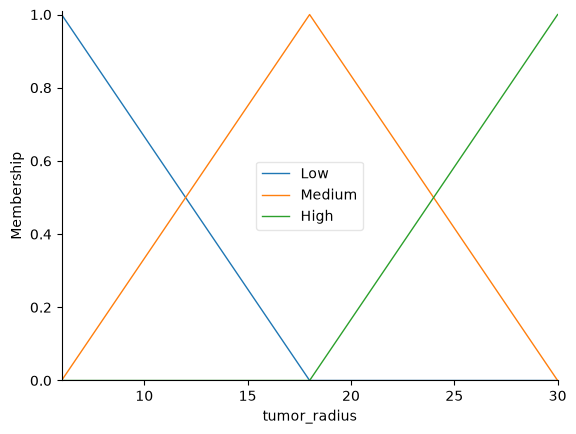

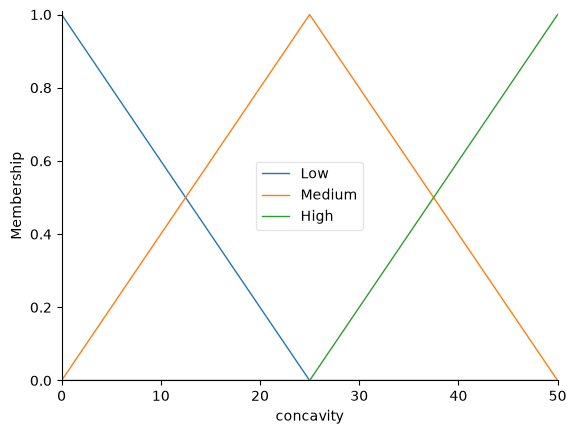

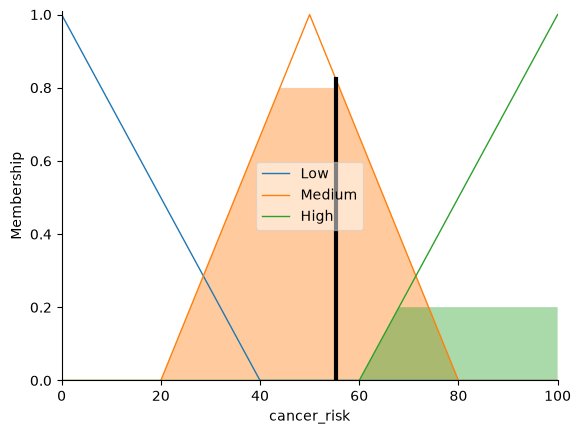

In [8]:
#Experiment 5 :Design of a Fuzzy Control System
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("/home/aditya/Downloads/data.csv")

# Define input and output variables
tumor_radius = ctrl.Antecedent(np.arange(6, 31, 1), 'tumor_radius')
concavity = ctrl.Antecedent(np.arange(0, 51, 1), 'concavity')
cancer_risk = ctrl.Consequent(np.arange(0, 101, 1), 'cancer_risk')

# Define membership functions
tumor_radius.automf(names=['Low', 'Medium', 'High'])
concavity.automf(names=['Low', 'Medium', 'High'])

cancer_risk['Low'] = fuzz.trimf(cancer_risk.universe, [0, 0, 40])
cancer_risk['Medium'] = fuzz.trimf(cancer_risk.universe, [20, 50, 80])
cancer_risk['High'] = fuzz.trimf(cancer_risk.universe, [60, 100, 100])

# Define fuzzy rules
rule1 = ctrl.Rule(
    tumor_radius['High'] | concavity['High'],
    cancer_risk['High']
)
rule2 = ctrl.Rule(
    tumor_radius['Medium'] & concavity['Medium'],
    cancer_risk['Medium']
)
rule3 = ctrl.Rule(
    tumor_radius['Low'] & concavity['Low'],
    cancer_risk['Low']
)
rule4 = ctrl.Rule(
    tumor_radius['Low'] & concavity['Medium'],
    cancer_risk['Medium']
)
rule5 = ctrl.Rule(
    tumor_radius['Medium'] & concavity['Low'],
    cancer_risk['Medium']
)
rule6 = ctrl.Rule(
    tumor_radius['Medium'] & concavity['High'],
    cancer_risk['High']
)
rule7 = ctrl.Rule(
    tumor_radius['High'] & concavity['Medium'],
    cancer_risk['High']
)

# Create fuzzy control system
risk_control = ctrl.ControlSystem([
    rule1, rule2, rule3, rule4, rule5, rule6, rule7
])
risk_simulation = ctrl.ControlSystemSimulation(risk_control)

# Take one sample from the existing dataset
sample = df.iloc[0]

radius_value = float(sample['radius_mean'])
concavity_value = float(sample['concavity_mean']) * 100

# Provide input values
risk_simulation.input['tumor_radius'] = np.clip(radius_value, 6, 30)
risk_simulation.input['concavity'] = np.clip(concavity_value, 0, 50)

# Calculate output
risk_simulation.compute()

print("Tumor Radius:", radius_value)
print("Concavity:", concavity_value)
print("Fuzzy Output Score:", round(risk_simulation.output['cancer_risk'], 2))

# Display membership functions
tumor_radius.view()
plt.show()

concavity.view()
plt.show()

cancer_risk.view(sim=risk_simulation)
plt.show()

/home/aditya/AIDS_EXP/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
E0000 00:00:1792088006.803981   28909 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7665 - loss: 0.5127 - val_accuracy: 0.8571 - val_loss: 0.4388
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8846 - loss: 0.3973 - val_accuracy: 0.9121 - val_loss: 0.3551
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9286 - loss: 0.3100 - val_accuracy: 0.9451 - val_loss: 0.2899
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9451 - loss: 0.2421 - val_accuracy: 0.9451 - val_loss: 0.2429
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9505 - loss: 0.1908 - val_accuracy: 0.9451 - val_loss: 0.2086
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9560 - loss: 0.1555 - val_accuracy: 0.9451 - val_loss: 0.1838
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9615 - loss: 0.1287 - val_accuracy: 0.9560 - val_loss: 0.1661
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9698 - loss: 0.1095 - val_accuracy: 0.9560 - val_loss

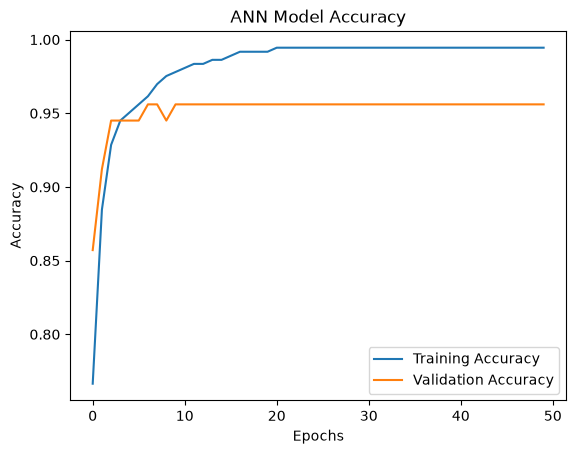

In [11]:
#Experiment 06 – Artificial Neural Network (ANN)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Load dataset
df = pd.read_csv("/home/aditya/Downloads/data.csv")

# Prepare input and output
X = df.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)
X = X.select_dtypes(include=[np.number]).fillna(0)

y = df["diagnosis"].map({"M": 1, "B": 0})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Build ANN model
model = Sequential([
    Dense(16, activation="relu", input_shape=(X_train.shape[1],)),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train model
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

# Predictions
y_pred_prob = model.predict(X_test, verbose=0)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Benign", "Malignant"]
))

# Plot accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("ANN Model Accuracy")
plt.legend()
plt.show()

Epoch 1/30


/home/aditya/AIDS_EXP/.venv/lib/python3.13/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8984 - loss: 0.3637 - val_accuracy: 0.9341 - val_loss: 0.1912
Epoch 2/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9533 - loss: 0.1562 - val_accuracy: 0.9670 - val_loss: 0.1340
Epoch 3/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9753 - loss: 0.0915 - val_accuracy: 0.9670 - val_loss: 0.1243
Epoch 4/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9780 - loss: 0.0799 - val_accuracy: 0.9670 - val_loss: 0.1141
Epoch 5/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9780 - loss: 0.0769 - val_accuracy: 0.9451 - val_loss: 0.1311
Epoch 6/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9698 - loss: 0.0726 - val_accuracy: 0.9451 - val_loss: 0.1237
Epoch 7/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9780 - loss: 0.0635 - val_accuracy: 0.9560 - val_loss: 0.1163
Epoch 8/30
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9808 - loss: 0.0659 - val_accuracy: 0.9560 - val_loss: 0.12

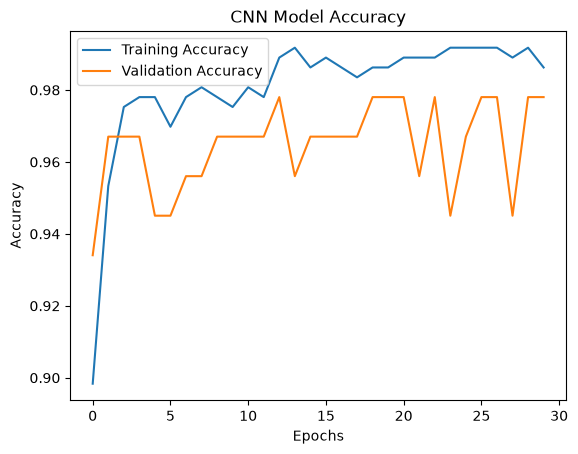

In [13]:
#Experiment 07 – Convolutional Neural Network (CNN)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout

# Load dataset
df = pd.read_csv("/home/aditya/Downloads/data.csv")

# Prepare input and output
X = df.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)
X = X.select_dtypes(include=[np.number]).fillna(0)

y = df["diagnosis"].map({"M": 1, "B": 0})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalize data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Reshape data for CNN: samples, features, channels
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# Build CNN model
model = Sequential([
    Conv1D(32, kernel_size=3, activation="relu",
           input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

# Compile model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train model
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

# Predictions
y_pred_prob = model.predict(X_test, verbose=0)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Benign", "Malignant"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot accuracy
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN Model Accuracy")
plt.legend()
plt.show()

Libraries imported successfully
Dataset loaded successfully
Dataset Shape: (569, 33)
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980   

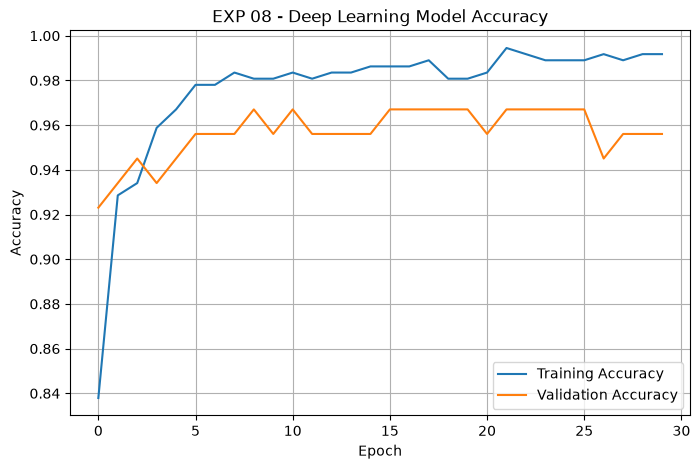


Deep Learning Application Results
----------------------------------
Test Loss: 0.0590960830450058
Test Accuracy (%): 98.24561476707458
Breast Cancer Classification Application Ready

Breast Cancer Classification Result
-----------------------------------
Actual Diagnosis: M
Predicted Diagnosis: Malignant
Model Confidence: 100.00%


/home/aditya/AIDS_EXP/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [22]:
# EXP 08 - Deep Learning Application for Breast Cancer Classification

# Import Libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Libraries imported successfully")

# Load Dataset
df = pd.read_csv("/home/aditya/Downloads/data.csv")

print("Dataset loaded successfully")
print("Dataset Shape:", df.shape)
print(df.head())

# Prepare Input and Output Data
X = df.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)

X = X.select_dtypes(include=[np.number])
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

y = df["diagnosis"].map({"M": 1, "B": 0})

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Normalize Input Data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data normalization completed successfully")

# Create Deep Learning Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

print("Deep learning model created successfully")

# Compile Model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully")

# Train Model
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

print("Model training completed successfully")

# Evaluate Model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

# Generate Predictions
y_pred_probability = model.predict(X_test, verbose=0)
y_pred = (y_pred_probability > 0.5).astype(int).flatten()

comparison = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})

print("\nActual vs Predicted:")
print(comparison.head(10))

# Plot Training and Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EXP 08 - Deep Learning Model Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Display Final Model Performance
print("\nDeep Learning Application Results")
print("----------------------------------")
print("Test Loss:", loss)
print("Test Accuracy (%):", accuracy * 100)

# Breast Cancer Classification Application
def predict_breast_cancer(features):
    features = np.asarray(features, dtype=float).reshape(1, -1)
    features_scaled = scaler.transform(features)

    probability = model.predict(features_scaled, verbose=0)[0][0]

    if probability >= 0.5:
        result = "Malignant"
        confidence = probability * 100
    else:
        result = "Benign"
        confidence = (1 - probability) * 100

    return result, confidence

print("Breast Cancer Classification Application Ready")

# Test Application with One Dataset Record
sample_features = df.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
).select_dtypes(include=[np.number]).iloc[0].values

actual_diagnosis = df["diagnosis"].iloc[0]

prediction, confidence = predict_breast_cancer(sample_features)

print("\nBreast Cancer Classification Result")
print("-----------------------------------")
print("Actual Diagnosis:", actual_diagnosis)
print("Predicted Diagnosis:", prediction)
print("Model Confidence: {:.2f}%".format(confidence))


Accuracy: 98.24561403508771 %

Classification Report:
              precision    recall  f1-score   support

      Benign       0.97      1.00      0.99        72
   Malignant       1.00      0.95      0.98        42

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Confusion Matrix:
 [[72  0]
 [ 2 40]]


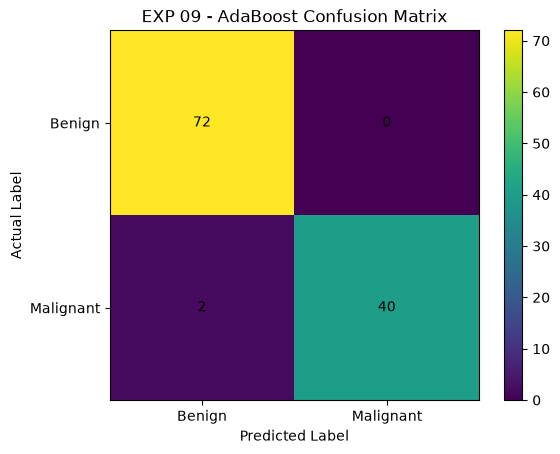

In [23]:
# EXP 09 - AdaBoost Classification Algorithm

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
df = pd.read_csv("/home/aditya/Downloads/data.csv")

# Prepare input and output
X = df.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)
X = X.select_dtypes(include=[np.number]).fillna(0)

y = df["diagnosis"].map({"M": 1, "B": 0})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create AdaBoost classifier
model = AdaBoostClassifier(
    n_estimators=50,
    learning_rate=1.0,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Predict output
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Benign", "Malignant"]
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Plot confusion matrix
plt.imshow(cm)
plt.title("EXP 09 - AdaBoost Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.yticks([0, 1], ["Benign", "Malignant"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

Accuracy: 97.36842105263158 %

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

Confusion Matrix:
 [[72  0]
 [ 3 39]]


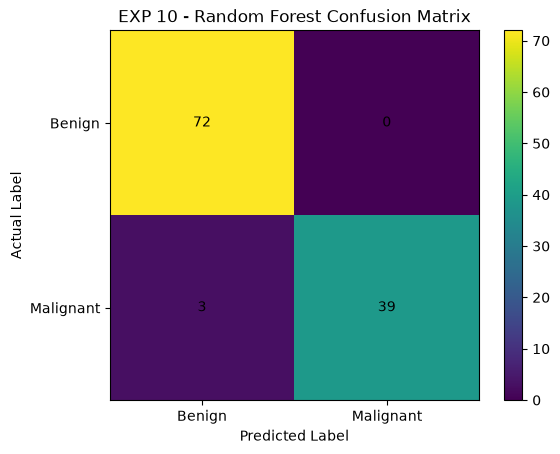

In [24]:
# EXP 10 - Random Forest Classification

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load Dataset
df = pd.read_csv("/home/aditya/Downloads/data.csv")

# Prepare Input and Output
X = df.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)
X = X.select_dtypes(include=[np.number]).fillna(0)

y = df["diagnosis"].map({"M": 1, "B": 0})

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Create Random Forest Model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Model
model.fit(X_train, y_train)

# Make Predictions
y_pred = model.predict(X_test)

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy * 100, "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Benign", "Malignant"]
))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Plot Confusion Matrix
plt.imshow(cm)
plt.title("EXP 10 - Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.yticks([0, 1], ["Benign", "Malignant"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

Dataset loaded successfully
Dataset Shape: (569, 33)
Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)

Classification Model Comparison:
              Model  Accuracy  Precision  Recall  F1 Score
           AdaBoost    0.9825     1.0000  0.9524    0.9756
      Random Forest    0.9737     1.0000  0.9286    0.9630
                SVM    0.9737     1.0000  0.9286    0.9630
Logistic Regression    0.9649     0.9750  0.9286    0.9512
                KNN    0.9561     0.9744  0.9048    0.9383
        Naive Bayes    0.9386     1.0000  0.8333    0.9091
      Decision Tree    0.9298     0.9048  0.9048    0.9048

Best Model: AdaBoost
Best Accuracy: 98.25 %
Precision: 1.0
Recall: 0.9524
F1 Score: 0.9756


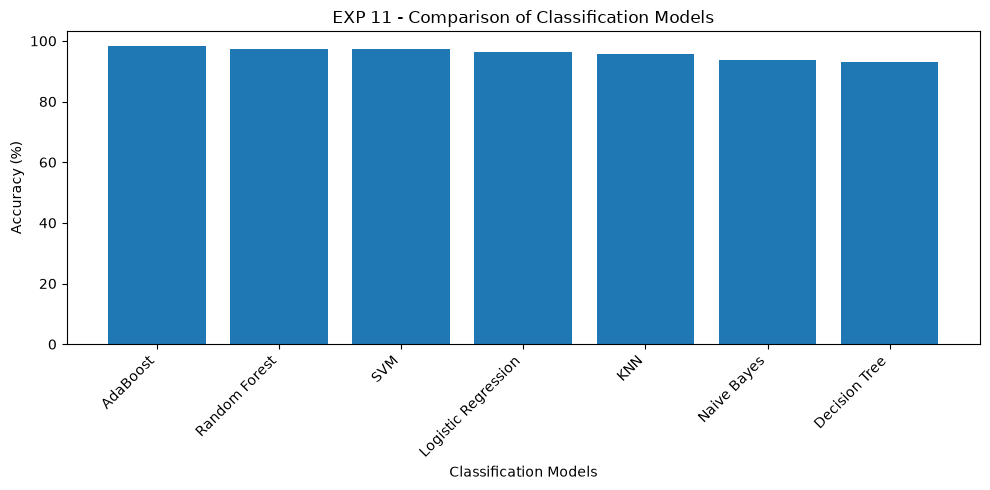

In [25]:
# EXP 11 - Comparison of Classification Models

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Load Dataset
df = pd.read_csv("/home/aditya/Downloads/data.csv")

print("Dataset loaded successfully")
print("Dataset Shape:", df.shape)

# Prepare Input and Output
X = df.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)

X = X.select_dtypes(include=[np.number])
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

y = df["diagnosis"].map({"M": 1, "B": 0})

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Define Classification Models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=50,
        random_state=42
    ),
    "Naive Bayes": GaussianNB()
}

# Train and Evaluate Models
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

# Display Comparison Table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

print("\nClassification Model Comparison:")
print(results_df.round(4).to_string(index=False))

# Identify Best Model
best_model = results_df.iloc[0]

print("\nBest Model:", best_model["Model"])
print("Best Accuracy:", round(best_model["Accuracy"] * 100, 2), "%")
print("Precision:", round(best_model["Precision"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))

# Plot Model Accuracy
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"] * 100
)

plt.xlabel("Classification Models")
plt.ylabel("Accuracy (%)")
plt.title("EXP 11 - Comparison of Classification Models")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
